In [1]:
from Bio import SeqIO, AlignIO, Phylo
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.Phylo.TreeConstruction import DistanceCalculator, DistanceTreeConstructor
import matplotlib.pyplot as plt
import subprocess, os

In [2]:
#Funciones reutilizables

def leer_fots(carpeta, n):
    fots = []
    for i in range(1, n + 1):
        registro = SeqIO.read(f'{carpeta}Fot{i}.fasta', 'fasta')
        if i == 5:
            registro = registro[787:2443]
            registro.description = 'Fot5 transponible element in Oxysporum'
        registro.id = f'Fot{i}'
        fots.append(registro)
    return fots


def ocultar_nodos_internos(clado):
    if clado.is_terminal():
        return clado.name
    else:
        return None


def alinear_y_arbol(entrada, salida, titulo, png, muscle='./muscle.exe'):
    comando = [muscle, '-in', entrada, '-out', salida]

    try:
        subprocess.run(comando, capture_output=True, text=True, check=True)
    except subprocess.CalledProcessError as e:
        print(f'Error al ejecutar MUSCLE: {e}')
        print(f'Salida del error: {e.stderr}')

    if not os.path.exists(salida):
        return None

    alineamiento = AlignIO.read(salida, 'fasta')
    print(f'Número de secuencias: {len(alineamiento)}')
    print(f'Longitud del alineamiento (con gaps): {alineamiento.get_alignment_length()}')
    print('\nVista previa del alineamiento:')
    print(alineamiento[:, :50])

    calculadora = DistanceCalculator('identity')
    matriz_dist = calculadora.get_distance(alineamiento)
    arbol = DistanceTreeConstructor().nj(matriz_dist)

    fig = plt.figure(figsize=(10, 6))
    axes = fig.add_subplot(1, 1, 1)
    axes.axis('off')
    plt.title(titulo, fontsize=14)
    Phylo.draw(arbol, axes=axes, do_show=False, label_func=ocultar_nodos_internos)
    plt.savefig(png, dpi=300, bbox_inches='tight')
    plt.show()
    return alineamiento

In [3]:
#Familia Fot: multifasta de ADN
fots = leer_fots('Fot/', 10)
for registro in fots:
    registro.description = ''
SeqIO.write(fots, 'Fot/Fot.fasta', 'fasta')

10

In [10]:
#Multifastas de Oxysporum y del conjunto de secuencias
skippy_oxys = SeqIO.read('Skippy/Skippy (Oxysporum).fasta', 'fasta')
folyt1_oxys = SeqIO.read('Folyt1/AF057141.1 (Folyt1).fasta', 'fasta')
impala_oxys = SeqIO.read('impala/impala (oxysporum).fasta', 'fasta')
otros_oxys = [skippy_oxys, folyt1_oxys, impala_oxys]

fots_oxys = leer_fots('Fot/', 5)
Oxysporum = otros_oxys + fots_oxys
SeqIO.write(Oxysporum, 'Oxysporum_multifasta.fasta', 'fasta')

skippy_verti = SeqIO.read('F.vertici (pseudo-skippy).fasta', 'fasta')
impala_fuji = SeqIO.read('F.fujikuroi (pseudo-impala).fasta', 'fasta')

Secuencias = otros_oxys + fots_oxys + [skippy_verti, impala_fuji]
SeqIO.write(Secuencias, 'Secuencias_multifasta.fasta', 'fasta')

10

In [11]:
#ORF más largo y traducción a proteína
def encontrar_orf_mas_largo(secuencia, min_aa=30):
    mejor_orf = None
    longitud_max = 0
    for strand, nuc in [(1, secuencia), (-1, secuencia.reverse_complement())]:
        for frame in range(3):
            proteina_completa = nuc[frame:].translate(table=1)
            fragmentos = proteina_completa.split('*')
            for frag in fragmentos:
                indice_m = frag.find('M')
                if indice_m != -1:
                    orf_biologico = frag[indice_m:]
                    if len(orf_biologico) > longitud_max and len(orf_biologico) >= min_aa:
                        longitud_max = len(orf_biologico)
                        mejor_orf = orf_biologico

    return mejor_orf


proteinas = []
for registro in Secuencias:
    orf = encontrar_orf_mas_largo(registro.seq)
    if orf:
        #print(f'ID: {registro.id} | ORF más largo: {len(orf)} aminoácidos')
        proteinas.append(SeqRecord(Seq(str(orf)),
                                   id=registro.id,
                                   description=registro.description + '(translated protein)'))
    else:
        print(f'ID: {registro.id} | No se detectó un ORF significativo')

SeqIO.write(proteinas, 'proteinas_TE.fasta', 'fasta')

C:\Users\Alber\anaconda3\Lib\site-packages\Bio\Seq.py:2877: BiopythonWarning: Partial codon, len(sequence) not a multiple of three. Explicitly trim the sequence or add trailing N before translation. This may become an error in future.
  warnings.warn(


10

Número de secuencias: 5
Longitud del alineamiento (con gaps): 623

Vista previa del alineamiento:
Alignment with 5 rows and 50 columns
-------------------------------------------------- Fot5
-------------------------------------------------- Fot2
MSVVLGSSFRLISSHCFFDYVCSMVARDQCKICQNVSFDTQPPRRSFQCS Fot3
-------------------------------------------------- Fot1
-------------------------------------------------- Fot4


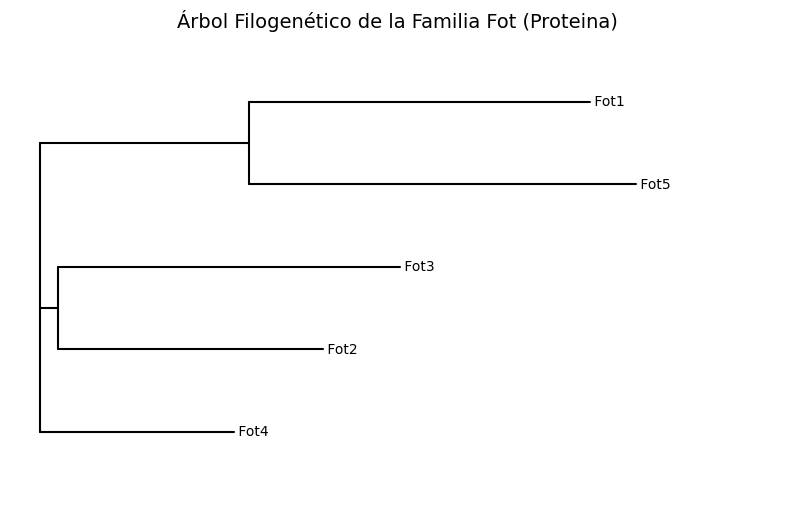

In [12]:
#Árbol de la familia Fot (proteína)
Fot_prot = [p for p in proteinas
            if 'fot' in p.id.lower() or 'fot' in p.description.lower()]
SeqIO.write(Fot_prot, 'Fot_prot.fasta', 'fasta')

alineamiento_fot_prot = alinear_y_arbol(
    'Fot_prot.fasta',
    'alineamiento_fot_prot.fasta',
    'Árbol Filogenético de la Familia Fot (Proteina)',
    'images/Arbol_Fot_Prot.png')

Número de secuencias: 10
Longitud del alineamiento (con gaps): 2888

Vista previa del alineamiento:
Alignment with 10 rows and 50 columns
-----------------------------ATCAATAAAGCAAACCCAGTA Fot8
-------------------------------------GTCGGTCAGAAGA Fot6
-----------CGCGCTGAGCTTAGTCACATTCGGAGGTCAGCTGTAAAA Fot9
-----------------------------ACCCATACTCCCAGTAAAGCG Fot7
-------------------------CTCGGCCCCGACTCCGGATATGCCA Fot10
------------------------------------AGTCAAGCACCCAT Fot1
-----------------------------------ATGTCAGA------- Fot5
-----------------------------------ACGTCGGATACGGGG Fot4
CCATGCAGTACCCACCTACCGGCAGTACCCACCTATCGGCAAGCAAAAAA Fot3
CCATATACGACCCCCCTTTCGACAGCCCCACCCTTTGGTCAAGCAAAAAA Fot2


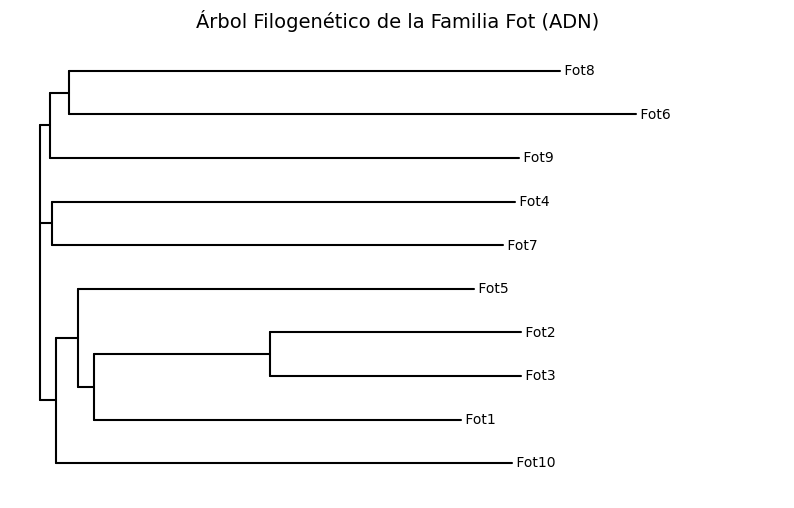

In [13]:
#Árbol de la familia Fot (ADN)
alineamiento = alinear_y_arbol(
    'Fot/Fot.fasta',
    'Fot/alineamiento_fot_ADN.fasta',
    'Árbol Filogenético de la Familia Fot (ADN)',
    'images/Arbol_Fot_ADN.png')

In [14]:
#TEF1: multifasta
archivos_tef1 = {
    'oxysporum': 'oxysporum.fasta',
    'fujikuroi': 'fujikuroi.fasta',
    'graminearum': 'graminearum.fasta',
    'verticillioides': 'verticillioides(comp).fasta',
    'solani': 'solani.fasta',
    'venenatum': 'venenatum.fasta',
    'culmorum': 'culmorum.fasta',
    'mangiferae': 'mangiferae.fasta',
}

tef1_por_especie = {}
for especie, archivo in archivos_tef1.items():
    registro = SeqIO.read(f'housekeeping/{archivo}', 'fasta')
    if especie == 'verticillioides':
        registro = registro[31:680]
    registro.id = f'{registro.id}({especie})'
    tef1_por_especie[especie] = registro

vertici_tef1 = tef1_por_especie['verticillioides']
tef1 = list(tef1_por_especie.values())
SeqIO.write(tef1, 'housekeeping/TEF1.fasta', 'fasta')

8

Número de secuencias: 8
Longitud del alineamiento (con gaps): 705

Vista previa del alineamiento:
Alignment with 8 rows and 50 columns
----------------------------------------CTCGAGT--- KY873573.1(culmorum)
----CCTCATCG-------------------------------------- KR673963.1(solani)
TCGTCGTCATCGGCCACGTCGACTCTGGCAAGTCGACCACTGTGAGTACT MN193873.1(verticillioides)
----------------------------------------TGTGAGT--- KM092484.1(oxysporum)
-CGTCGTCATCGGCCACGTCGACTCTGGCAAGTCGACCACTGTGAGTACT OK422231.1(fujikuroi)
-CGTCGTCATCGGCCACGTCGACTCTGGCAAGTCGACCACTGTGAGTACT OK422236.1(mangiferae)
TCGTCGTCATCGGCCACGTCGACTCTGGCAAGTCGACCACTGTGAGTACC MW233103.1(graminearum)
TCGTCGTCATCGGCCACGTCGACTCTGGCAAGTCGACCACTGTAAGTACA MW233109.1(venenatum)


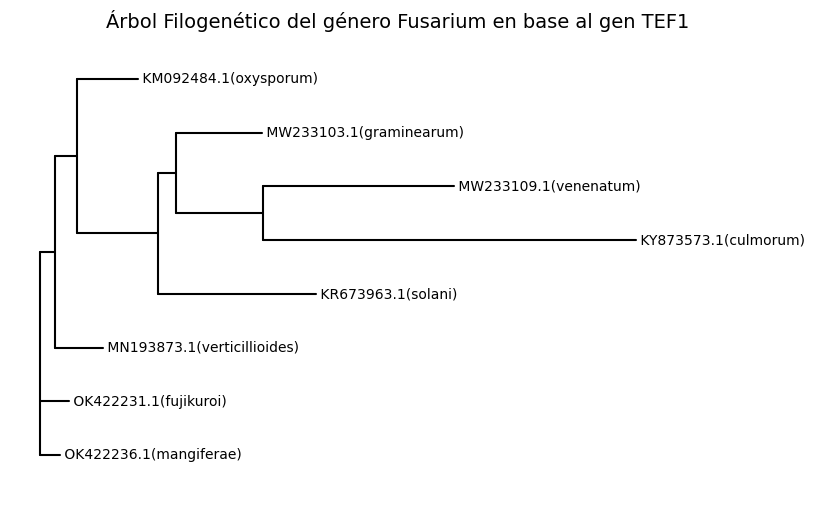

In [15]:
#TEF1: árbol del género Fusarium
alineamiento = alinear_y_arbol(
    'housekeeping/TEF1.fasta',
    'housekeeping/alineamiento_tef1.fasta',
    'Árbol Filogenético del género Fusarium en base al gen TEF1',
    'images/Arbol_Fusarium.png')

In [16]:
print(format(alineamiento))
len(vertici_tef1.seq)

Alignment with 8 rows and 705 columns
----------------------------------------CTCG...--- KY873573.1(culmorum)
----CCTCATCG--------------------------------...--- KR673963.1(solani)
TCGTCGTCATCGGCCACGTCGACTCTGGCAAGTCGACCACTGTG...TGA MN193873.1(verticillioides)
----------------------------------------TGTG...T-- KM092484.1(oxysporum)
-CGTCGTCATCGGCCACGTCGACTCTGGCAAGTCGACCACTGTG...TGG OK422231.1(fujikuroi)
-CGTCGTCATCGGCCACGTCGACTCTGGCAAGTCGACCACTGTG...TGG OK422236.1(mangiferae)
TCGTCGTCATCGGCCACGTCGACTCTGGCAAGTCGACCACTGTG...--- MW233103.1(graminearum)
TCGTCGTCATCGGCCACGTCGACTCTGGCAAGTCGACCACTGTA...--- MW233109.1(venenatum)


649

In [17]:
#Carotenoides: concatenar carB + carO + carX por especie
def unir_genes_car(especie):
    genes = [SeqIO.read(f'Carotenoides/{especie}/{gen}.fasta', 'fasta')
             for gen in ('carB', 'carO', 'carX')]
    car = genes[0] + genes[1] + genes[2]
    car.id = f'Fusarium_{especie}'
    car.description = 'carB_carO_carX'
    return car


especies_car = ['culmorum', 'fujikuroi', 'graminearum', 'mangiferae',
                'oxysporum', 'solani', 'venenatum', 'verticillioides']
car_por_especie = {esp: unir_genes_car(esp) for esp in especies_car}

print(car_por_especie['oxysporum'])

car = list(car_por_especie.values())
for registro in car:
    registro.description = ''
SeqIO.write(car, 'Carotenoides/carotenoides.fasta', 'fasta')

ID: Fusarium_oxysporum
Name: <unknown name>
Description: carB_carO_carX
Number of features: 0
Seq('ATGAGCGACATTAAGAAATCTGTTATTATTATTGGTGCTGGTGTCGGTGGTGTT...TAA')


8

Número de secuencias: 8
Longitud del alineamiento (con gaps): 8191

Vista previa del alineamiento:
Alignment with 8 rows and 50 columns
-------------------------------------------------- Fusarium_solani
-------------------------------------------------- Fusarium_graminearum
-------------------------------------------------- Fusarium_venenatum
-------------------------------------------------- Fusarium_culmorum
-------------------------------------------------- Fusarium_verticillioides
-------------------------------------------------- Fusarium_oxysporum
TGGGGTGAAGCGTGGAGGATGTAATGGTAGAGGTCATAGATTCATAGATT Fusarium_fujikuroi
-------------------------------------------------- Fusarium_mangiferae


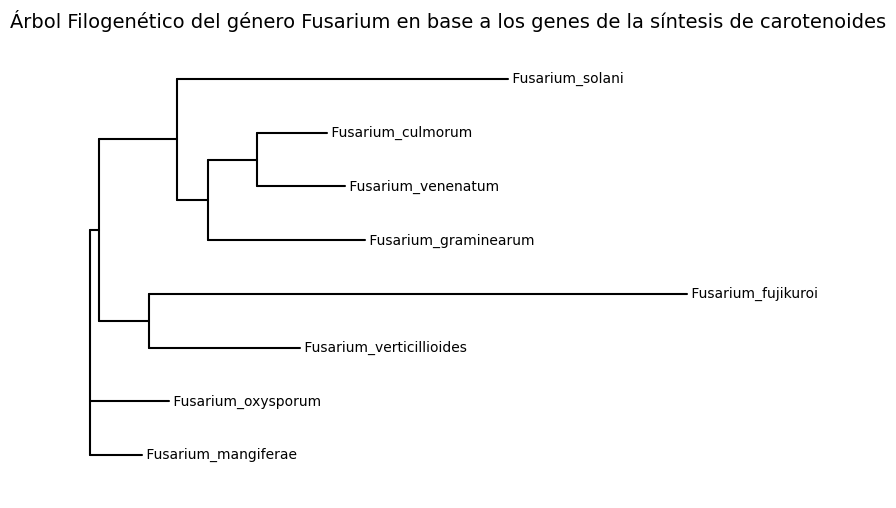

In [18]:
#Carotenoides: árbol
alineamiento = alinear_y_arbol(
    'Carotenoides/carotenoides.fasta',
    'Carotenoides/carotenoides_alineamiento.fasta',
    'Árbol Filogenético del género Fusarium en base a los genes de la síntesis de carotenoides',
    'images/Arbol_Fusarium_car.png')